# **Combine two Bridge Grades snapshot files into a single master dataset**

> Each snapshot contains the same legislator base structure and a single column
named 'Bridge_Grade'. This script merges both snapshots into one dataframe
and adds a distinct column for each date (e.g., 'Bridge_Grade_2025_10_19').

In [1]:
import pandas as pd

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
"""
Combine multiple Bridge Grades snapshot files into a clean master dataset.

Each snapshot contains identical legislator metadata and columns named
'Bridge_Grade' and 'Bridge_Score'. This script merges all snapshots
so that metadata appears once and each snapshot adds its grade and score columns.
"""

import pandas as pd

# === Configuration ===
snapshots = {
    "2026_03_23": "/content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_06_02/Data/ congress_scores_119_single_sheet_2026-03-23.xlsx",
    "2026_03_31": "/content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_06_02/Data/congress_scores_119_single_sheet_2026-03-31.xlsx",
    "2026_05_01": "/content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_06_02/Data/congress_scores_119_single_sheet_2026-05-01.xlsx",
    "2026_06_02": "/content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_06_02/Data/congress_scores_119_single_sheet_2026-06-02.xlsx",
}

output_path = "/content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_06_02/Bridge_Grades_Snapshot_Scorecard_2026_06_02.xlsx"

# === Functions ===
def find_column(df, keyword):
    """Find the column that contains a given keyword (case-insensitive)."""
    for col in df.columns:
        if keyword.lower() in col.lower():
            return col
    return None

# Metadata columns that should appear only once
metadata_columns = [
    "bioguide_id", "Chamber", "Name", "first_name", "middle_name",
    "last_name", "nickname", "State", "State_Abbr", "Party"
]

merged_df = None
snapshots_data = {}

# === Process snapshots ===
for date, path in snapshots.items():
    print(f"\nProcessing snapshot {date}...")
    df = pd.read_excel(path)

    # Light cleanup of column names (whitespace, etc.)
    df.columns = df.columns.str.strip()

    score_col = find_column(df, "Bridge_Score")
    grade_col = find_column(df, "Bridge_Grade")

    if not grade_col or not score_col:
        raise ValueError(f"Could not find Bridge_Grade or Bridge_Score in {path}")

    # Rename score/grade columns for this snapshot
    df = df.rename(columns={
        score_col: f"Bridge_Score_{date}",
        grade_col: f"Bridge_Grade_{date}"
    })

    # For the first snapshot we include full metadata;
    # for subsequent ones, only bioguide_id + new score/grade columns
    if merged_df is None:
        base_cols = metadata_columns + [f"Bridge_Score_{date}", f"Bridge_Grade_{date}"]
    else:
        base_cols = ["bioguide_id", f"Bridge_Score_{date}", f"Bridge_Grade_{date}"]

    df_base = df[base_cols].copy()
    df_base = df_base.loc[:, ~df_base.columns.duplicated()]

    snapshots_data[date] = set(df_base["bioguide_id"].dropna())

    if merged_df is None:
        merged_df = df_base
    else:
        # Here there are NO duplicate metadata columns, only bioguide_id + new metrics
        merged_df = pd.merge(merged_df, df_base, on="bioguide_id", how="outer")

# === Clean duplicates and fill metadata (just in case) ===
for col in metadata_columns:
    if col not in merged_df.columns:
        continue
    # Fill missing metadata using first non-null value (in this case it should be trivial)
    merged_df[col] = merged_df.filter(regex=f'^{col}$').bfill(axis=1).iloc[:, 0]

# Keep only the clean columns
final_columns = metadata_columns + [
    col for col in merged_df.columns
    if col.startswith("Bridge_Score_") or col.startswith("Bridge_Grade_")
]
merged_df = merged_df[final_columns]

# === Sort and export ===
merged_df = merged_df.sort_values(by=["State_Abbr", "last_name"]).reset_index(drop=True)
merged_df.to_excel(output_path, index=False, engine="openpyxl")

print("\nFile successfully generated.")
print(f"Saved to: {output_path}")
print(f"Total legislators combined: {len(merged_df)}")
print(f"Total snapshots merged: {len(snapshots)}")

# === Verify missing legislators ===
print("\nChecking for missing legislators across snapshots...")
all_ids = set().union(*snapshots_data.values())
presence = pd.DataFrame({"bioguide_id": list(all_ids)})

for date, ids in snapshots_data.items():
    presence[date] = presence["bioguide_id"].isin(ids).astype(int)

presence["Snapshots_Present"] = presence[list(snapshots.keys())].sum(axis=1)
incomplete = presence[presence["Snapshots_Present"] < len(snapshots)]

print(f"\nLegislators missing in one or more snapshots: {len(incomplete)}")
if not incomplete.empty:
    print("\nExample of missing entries:")
    print(incomplete.head(10))
else:
    print("\nAll legislators are present across all snapshots.")



Processing snapshot 2026_03_23...

Processing snapshot 2026_03_31...

Processing snapshot 2026_05_01...

Processing snapshot 2026_06_02...

File successfully generated.
Saved to: /content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_06_02/Bridge_Grades_Snapshot_Scorecard_2026_06_02.xlsx
Total legislators combined: 531
Total snapshots merged: 4

Checking for missing legislators across snapshots...

Legislators missing in one or more snapshots: 8

Example of missing entries:
    bioguide_id  2026_03_23  2026_03_31  2026_05_01  2026_06_02  \
0       S001193           1           1           0           0   
66      M001190           1           0           0           0   
159     F000485           0           0           1           0   
209     M001245           0           0           0           1   
222     S001157           1           1           0           0   
255     C001127           1           1           0           0   
440     M0012

In [ ]:
import pandas as pd

# === Configuration ===
snapshots = {
    "119.1": "/content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_03_23/Data/congress_scores_119_single_sheet_2026-03-23_V1.0.2.xlsx",
    "119.2": "/content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_03_23/Data/congress_scores_119_single_sheet_2026-03-23_V1.5.2.xlsx",
}

output_path = "/content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_03_23/Bridge_Grades_Snapshot_Scorecard_2026_03_23_ComparisonA.xlsx"

# Metadata
metadata_columns = [
    "bioguide_id", "Chamber", "Name", "first_name", "middle_name",
    "last_name", "nickname", "State", "State_Abbr", "Party"
]

# Define the data columns we want to extract from each file
col_norm_orig = "A_norm"
col_num_orig = "A: num_bills_with_cross_party_cosponsors"

merged_df = None
data_cols_added = []

# === Process snapshots ===
for version, path in snapshots.items():
    print(f"Processing version {version}...")

    df = pd.read_excel(path)
    df.columns = df.columns.str.strip()

    # New names for the columns
    new_norm_name = f"{version}_Anorm"
    new_num_name = f"{version}_Anum"

    # Columns to extract from this specific file
    target_cols = [col_norm_orig, col_num_orig]

    # Validate existence
    for c in target_cols:
        if c not in df.columns:
            raise ValueError(f"Column '{c}' not found in file: {path}")

    # Rename to avoid collisions in the merge
    df_subset = df[["bioguide_id"] + target_cols].copy()
    df_subset = df_subset.rename(columns={
        col_norm_orig: new_norm_name,
        col_num_orig: new_num_name
    })

    if merged_df is None:
        # First file: full metadata + data columns
        meta_present = [c for c in metadata_columns if c in df.columns]
        merged_df = pd.merge(df[meta_present], df_subset, on="bioguide_id", how="outer")
    else:
        # Subsequent: only bioguide_id + data columns
        merged_df = pd.merge(merged_df, df_subset, on="bioguide_id", how="outer")

    # Save the names for the final ordering
    data_cols_added.extend([new_norm_name, new_num_name])

# === Sort and export ===
# Reorder: metadata first, then data
final_cols = [c for c in metadata_columns if c in merged_df.columns] + data_cols_added
merged_df = merged_df[final_cols]

# Sort rows by state and last name
merged_df = merged_df.sort_values(by=["State_Abbr", "last_name"]).reset_index(drop=True)

# Save
merged_df.to_excel(output_path, index=False, engine="openpyxl")

print("\n--- Proceso Completado ---")
print(f"File saved: {output_path}")
print(f"Data columns added: {data_cols_added}")

Procesando versión 119.1...
Procesando versión 119.2...

--- Proceso Completado ---
Archivo guardado: /content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_03_23/Bridge_Grades_Snapshot_Scorecard_2026_03_23_ComparisonA.xlsx
Columnas de datos añadidas: ['119.1_Anorm', '119.1_Anum', '119.2_Anorm', '119.2_Anum']


In [ ]:
col_objetivo = "119.2_Anum"

house_only = merged_df[merged_df['Chamber'].str.contains('House', case=False, na=False)].copy()

resumen_proyectos = house_only.groupby('Party')[col_objetivo].sum().reset_index()

resumen_proyectos = resumen_proyectos.sort_values(by=col_objetivo, ascending=False)

print("=== TOTAL BILLS WITH BIPARTISAN COSPONSORSHIP (119.2 - HOUSE) ===")
print(resumen_proyectos.to_string(index=False))

=== TOTAL DE PROYECTOS CON CO-PATROCINIO BIPARTIDISTA (119.2 - HOUSE) ===
      Party  119.2_Anum
 Republican      1649.1
 Democratic      1391.0
Independent         4.0


In [ ]:
import pandas as pd

# === Configuration ===
snapshots = {
    "119.1": "/content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_03_23/Data/congress_scores_119_single_sheet_2026-03-23_V1.0.2.xlsx",
    "119.2": "/content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_03_23/Data/congress_scores_119_single_sheet_2026-03-23_V1.5.2.xlsx",
}

# Name of the final file with ComparisonB
output_path = "/content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_03_23/Bridge_Grades_Snapshot_Scorecard_2026_03_23_ComparisonB.xlsx"

# Requested metadata
metadata_columns = [
    "bioguide_id", "Chamber", "Name", "first_name", "middle_name",
    "last_name", "nickname", "State", "State_Abbr", "Party"
]

# Original columns to look up
col_norm_orig = "B_norm"
col_num_orig = "B: num_cross_party_cosponsored_bills"

merged_df = None
data_cols_added = []

# === Process snapshots ===
for version, path in snapshots.items():
    print(f"Processing version {version} for B metrics...")

    df = pd.read_excel(path)
    df.columns = df.columns.str.strip()

    # New names for the final columns
    new_norm_name = f"{version}_Bnorm"
    new_num_name = f"{version}_Bnum"

    # Validate existence of the columns
    for c in [col_norm_orig, col_num_orig]:
        if c not in df.columns:
            raise ValueError(f"Column '{c}' not found in file: {path}")

    # Extract and rename
    df_subset = df[["bioguide_id", col_norm_orig, col_num_orig]].copy()
    df_subset = df_subset.rename(columns={
        col_norm_orig: new_norm_name,
        col_num_orig: new_num_name
    })

    if merged_df is None:
        # First file: metadata + data columns
        meta_present = [c for c in metadata_columns if c in df.columns]
        merged_df = pd.merge(df[meta_present], df_subset, on="bioguide_id", how="outer")
    else:
        # Subsequent: only bioguide_id + data columns
        merged_df = pd.merge(merged_df, df_subset, on="bioguide_id", how="outer")

    data_cols_added.extend([new_norm_name, new_num_name])

# === Sort and export ===
# Metadata first, then B columns in order
final_cols = [c for c in metadata_columns if c in merged_df.columns] + data_cols_added
merged_df = merged_df[final_cols]

# Sort by state and last name
merged_df = merged_df.sort_values(by=["State_Abbr", "last_name"]).reset_index(drop=True)

merged_df.to_excel(output_path, index=False, engine="openpyxl")

print(f"\nFile saved: {output_path}")

Procesando versión 119.1 para métricas B...
Procesando versión 119.2 para métricas B...

Archivo guardado: /content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_03_23/Bridge_Grades_Snapshot_Scorecard_2026_03_23_ComparisonB.xlsx


In [ ]:
# === Analysis chunk: sum of B_num (119.2) by House and Party ===

# 1. Define the target column (count of B bills from v119.2)
col_objetivo = "119.2_Bnum"

# 2. Filter the DataFrame to get only 'House' records
house_only = merged_df[merged_df['Chamber'].str.contains('House', case=False, na=False)].copy()

# 3. Group by 'Party' and sum the B_num column
resumen_proyectos_B = house_only.groupby('Party')[col_objetivo].sum().reset_index()

# 4. Sort from highest to lowest
resumen_proyectos_B = resumen_proyectos_B.sort_values(by=col_objetivo, ascending=False)

# 5. Print the result
print("=== TOTAL OF B: NUM_CROSS_PARTY_COSPONSORED_BILLS (119.2 - HOUSE) ===")
print(resumen_proyectos_B.to_string(index=False))

=== TOTAL DE B: NUM_CROSS_PARTY_COSPONSORED_BILLS (119.2 - HOUSE) ===
      Party  119.2_Bnum
 Democratic   5459.6525
 Republican   3366.3800
Independent     12.4025


In [ ]:
# === Analysis chunk: sum of B_num (119.2) by House and Party ===

# 1. Define the target column (count of B bills from v119.2)
col_objetivo = "119.2_Bnum"

# 2. Filter the DataFrame to get only 'House' records
house_only = merged_df[merged_df['Chamber'].str.contains('Senate', case=False, na=False)].copy()

# 3. Group by 'Party' and sum the B_num column
resumen_proyectos_B = house_only.groupby('Party')[col_objetivo].sum().reset_index()

# 4. Sort from highest to lowest
resumen_proyectos_B = resumen_proyectos_B.sort_values(by=col_objetivo, ascending=False)

# 5. Print the result
print("=== TOTAL OF B: NUM_CROSS_PARTY_COSPONSORED_BILLS (119.2 - HOUSE) ===")
print(resumen_proyectos_B.to_string(index=False))

=== TOTAL DE B: NUM_CROSS_PARTY_COSPONSORED_BILLS (119.2 - HOUSE) ===
      Party  119.2_Bnum
 Democratic   1071.7050
 Republican    831.5025
Independent     43.7075


In [ ]:
print("\nFull details of missing legislator(s):")
print(incomplete.merge(merged_df, on="bioguide_id", how="left")[["bioguide_id", "Name", "Party"]])


Full details of missing legislator(s):
Empty DataFrame
Columns: [bioguide_id, Name, Party]
Index: []


In [ ]:
missing = incomplete.merge(merged_df, on="bioguide_id", how="left")[["bioguide_id", "Name", "Party"]]
for _, row in missing.iterrows():
    print(f"\nMissing record check for {row['Name']} ({row['bioguide_id']}):")
    for date in snapshots.keys():
        present = presence.loc[presence["bioguide_id"] == row["bioguide_id"], date].values[0]
        status = "✅ Present" if present == 1 else "❌ Missing"
        print(f"  {date}: {status}")


Mikie Sherril - Retired //
Doug LaMalfa - Passed away //
Marjorie Taylor Greene - Retired

La media de las diferencias entre versiones es: -0.21674012908978935


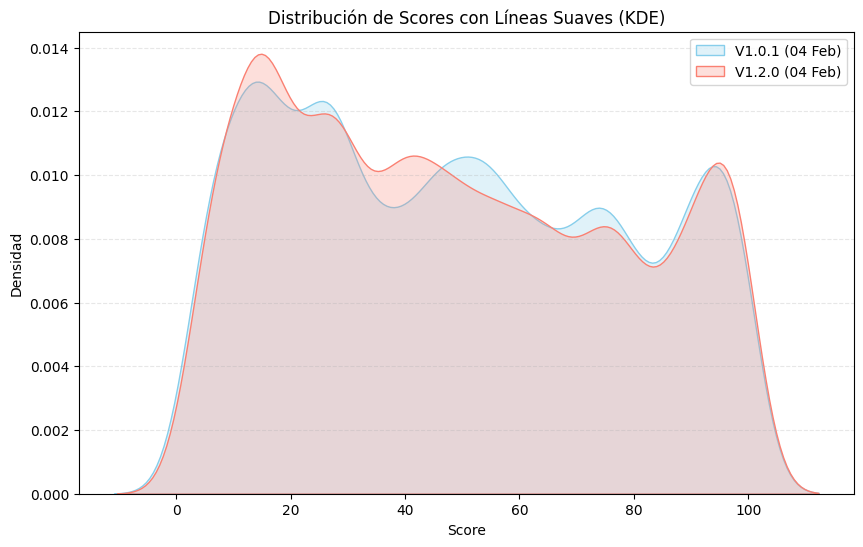

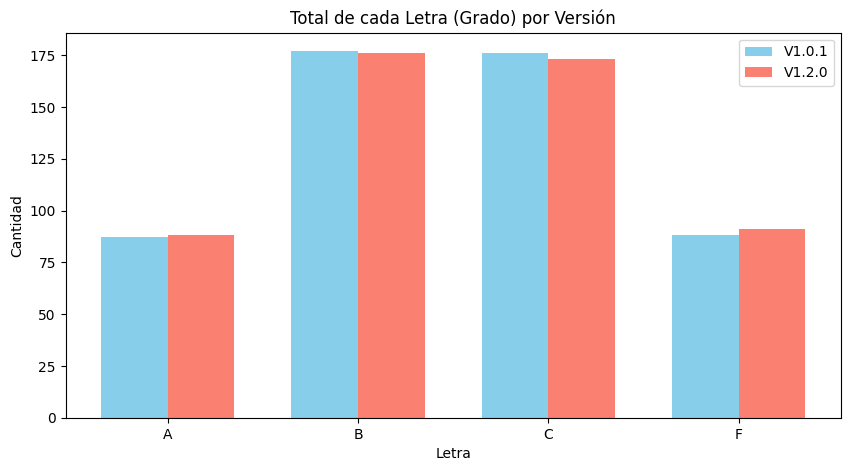

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


df = pd.read_excel("/content/drive/Shareddrives/Data Archive/Bridge_Grades/Scorecards/V1/Snapshot_Scorecard_2026_02_04/Bridge_Grades_Snapshot_Scorecard_2026_02_04_V.xlsx")

plt.figure(figsize=(10, 6))
# Use sns.kdeplot for the smoothed curves
sns.kdeplot(df['Bridge_Score_2026_02_04'], label='V1.0.1 (04 Feb)', fill=True, color='skyblue', bw_adjust=0.5)
sns.kdeplot(df['Bridge_Score_2026_02_04_V'], label='V1.2.0 (04 Feb)', fill=True, color='salmon', bw_adjust=0.5)

plt.title('Score Distribution with Smoothed Lines (KDE)')
plt.xlabel('Score')
plt.ylabel('Densidad')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.savefig('score_kde_distribution.png')

# --- 3. Mean of the differences ---
df['Diferencia'] = df['Bridge_Score_2026_02_04_V'] - df['Bridge_Score_2026_02_04']
media_diferencia = df['Diferencia'].mean()
print(f"The mean of the differences between versions is: {media_diferencia}")

# --- 4. Bar chart of totals by letter grade ---
# Count the frequency of each letter grade
counts_v1 = df['Bridge_Grade_2026_02_04'].value_counts().sort_index()
counts_v2 = df['Bridge_Grade_2026_02_04_V'].value_counts().sort_index()

# Align the indices to ensure all letter grades appear
all_labels = sorted(list(set(counts_v1.index) | set(counts_v2.index)))
counts_v1 = counts_v1.reindex(all_labels, fill_value=0)
counts_v2 = counts_v2.reindex(all_labels, fill_value=0)

x = np.arange(len(all_labels))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, counts_v1, width, label='V1.0.1', color='skyblue')
plt.bar(x + width/2, counts_v2, width, label='V1.2.0', color='salmon')
plt.xticks(x, all_labels)
plt.title('Total of Each Letter (Grade) by Version')
plt.xlabel('Letter')
plt.ylabel('Cantidad')
plt.legend()
plt.savefig('grade_distribution.png')
plt.show()

In [ ]:
import pandas as pd

# Assume your dataframe is called 'df'
# Compute the difference (new version - old version)
# A negative result means the score went down.
df['Diferencia'] = df['Bridge_Score_2026_02_04_V'] - df['Bridge_Score_2026_02_04']

# 1. Find the "biggest loser" (largest drop / most negative value)
mayor_perdedor = df.loc[df['Diferencia'].idxmin()]

# 2. Find the "biggest absolute change" (who moved the most, up or down)
df['Cambio_Absoluto'] = df['Diferencia'].abs()
mayor_cambio = df.loc[df['Cambio_Absoluto'].idxmax()]

print("--- CHANGE ANALYSIS ---")
print(f"The biggest loser dropped: {mayor_perdedor['Diferencia']:.4f} points.")
print(f"Puntaje anterior: {mayor_perdedor['Bridge_Score_2026_02_04']:.4f}")
print(f"Puntaje nuevo: {mayor_perdedor['Bridge_Score_2026_02_04_V']:.4f}")
print("The biggest loser is: " + mayor_perdedor['bioguide_id'])
print("-" * 30)
print(f"The record with the most drastic (absolute) change was: {mayor_cambio['Diferencia']:.4f} points.")

--- ANALISIS DE CAMBIOS ---
El mayor perdedor bajó: -48.7637 puntos.
Puntaje anterior: 64.2191
Puntaje nuevo: 15.4554
el peor perdedor es:G000601
------------------------------
El registro con el cambio más drástico (absoluto) fue de: -48.7637 puntos.


In [ ]:
df['difieren'] = df['Bridge_Grade_2026_02_04_V'] != df['Bridge_Grade_2026_02_04']

In [ ]:
df['difieren'].value_counts()

,count
difieren,
False,481
True,50
